In [13]:
import thinkbayes
import numpy as np
import matplotlib.pyplot as plt

USE_SUMMARY_DATA = True

class Hockey(thinkbayes.Suite):
    def __init__(self, name=''):
        if USE_SUMMARY_DATA:
            # prior based on each team's average goals scored
            mu = 2.8
            sigma = 0.3
        else:
            # prior based on each pair-wise match-up
            mu = 2.8
            sigma = 0.85

        pmf = thinkbayes.MakeGaussianPmf(mu, sigma, 4)
        thinkbayes.Suite.__init__(self, pmf, name=name)

    def Likelihood(self, data, hypo):
        lam = hypo
        k = data
        like = thinkbayes.EvalPoissonPmf(k, lam)
        return like

    
def MakeGoalPmf(suite, high=10):
    metapmf = thinkbayes.Pmf()

    for lam, prob in suite.Items():
        pmf = thinkbayes.MakePoissonPmf(lam, high)
        metapmf.Set(pmf, prob)
        
    mix = thinkbayes.MakeMixture(metapmf, name=suite.name)
    return mix

In [14]:
suite1 = Hockey('bruins')
suite2 = Hockey('canucks')

suite1.UpdateSet([0,2,8,4])
suite2.UpdateSet([1,3,1,0])

goal_dist1 = MakeGoalPmf(suite1)
goal_dist2 = MakeGoalPmf(suite2)

diff = goal_dist1 - goal_dist2


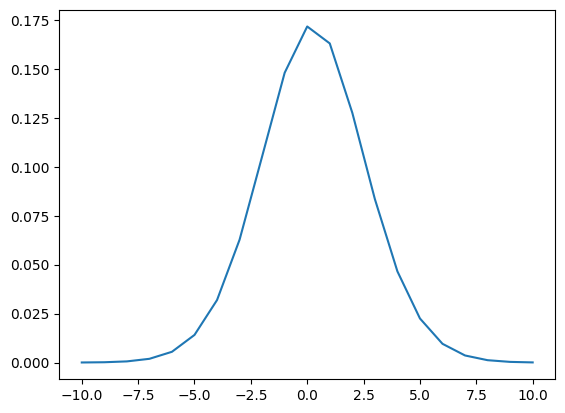

In [15]:
diff_lam, diff_prob = zip(*sorted(diff.Items()))
plt.plot(diff_lam, diff_prob)

In [19]:
p_win = diff.ProbGreater(0)
p_loss = diff.ProbLess(0)
p_tie = diff.Prob(0)

print(f"{p_win:.2f}, {p_loss:.2f}, {p_tie:.2f}")

0.46, 0.37, 0.17
